# Identification des paramètres thermiques par perceptron multicouche (MLP)

## Objectif de l'expérience

Cette expérience étudie un **perceptron multicouche (MLP)** pour estimer les propriétés thermiques d'un bâtiment à partir de caractéristiques statistiques extraites des signaux de température intérieure $T(t)$ et de sollicitation thermique $U(t)$.

Contrairement aux modèles CNN, qui exploitent directement les séries temporelles, le MLP utilise **58 caractéristiques sélectionnées lors du prétraitement**, décrivant notamment les variations de température, les sollicitations appliquées et leur évolution temporelle.

L'objectif est d'évaluer la capacité de cette représentation statistique à prédire les indicateurs thermiques et de disposer d'un modèle de référence pour la comparaison avec les architectures temporelles et hybrides.

## 1. Environnement d'exécution

Les fonctions de chargement des données, de définition des modèles, d'entraînement et d'évaluation sont regroupées dans `src/coenergy/`.

Cette organisation modulaire permet de réutiliser les mêmes composants entre les différentes expériences et d'assurer la reproductibilité des résultats.

In [ ]:

from pathlib import Path
import sys
import shutil

import torch
from IPython.display import display


def find_source_directory():
    """Localise le dossier contenant les modules du projet."""

    # Recherche sur le PC
    current_directory = Path.cwd()

    for directory in [current_directory, *current_directory.parents]:
        source_directory = directory / "src"

        if (source_directory / "coenergy" / "loss.py").is_file():
            return source_directory

    # Recherche sur Kaggle
    kaggle_directory = Path("/kaggle/input")

    if kaggle_directory.exists():
        for file in kaggle_directory.rglob("loss.py"):
            if file.parent.name == "coenergy":
                return file.parent.parent

    raise FileNotFoundError("Modules coEnergy introuvables.")


source_directory = find_source_directory()
sys.path.insert(0, str(source_directory))

from coenergy.data import load_data, BatchStore
from coenergy.models import build_model
from coenergy.loss import reconstruct_six, family_loss
from coenergy.training import default_config, seed_everything, Experiment
from coenergy.evaluation import evaluate_all, extreme_diagnostics
from coenergy.plotting import plot_training, plot_scores, plot_scatter

print("Modules coEnergy chargés avec succès.")
print("Chemin :", source_directory)
print("GPU disponible :", torch.cuda.is_available())


Modules coEnergy chargés avec succès.
Données : /kaggle/input/datasets/bilalaouiss/donnes
Modules : /kaggle/input/datasets/bilalaouiss/modules/src
GPU disponible : True
Manifest présent : True


## 2. Configuration expérimentale

L'entraînement du MLP repose sur **100 époques**, des mini-batchs de **1 024 simulations** et l'optimiseur **AdamW**, avec un taux d'apprentissage initial de **0,001**, ajusté selon la perte de validation. Aucun arrêt anticipé n'est appliqué.

Les hyperparamètres sont définis dans `training.py` et conservés identiques à ceux des modèles de référence afin de garantir une comparaison cohérente.

Une graine aléatoire fixe (**2026**) et un identifiant d'expérience (`RUN_ID`) facilitent la reproductibilité et la traçabilité des entraînements.

In [ ]:
MODEL_KIND = "mlp"
RUN_ID = "run_001"
DATA_ROOT = (
    Path("/kaggle/input/datasets/bilalaouiss/dataset")
    if Path("/kaggle/input/datasets/bilalaouiss/dataset").is_dir()
    else None
)
RUN_TRAINING = True
RESUME = True

config = default_config(MODEL_KIND, RUN_ID)
seed_everything(config.seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if Path("/kaggle/working").is_dir():
    results_directory = Path("/kaggle/working/results")
else:
    results_directory = source_directory.parent / "results"

output_directory = results_directory / MODEL_KIND / RUN_ID

print("Modèle :", MODEL_KIND)
print("Appareil :", device)
print("Époques :", config.max_epochs)
print("Taille des mini-batchs :", config.batch_size)
print("Résultats :", output_directory)


Modèle : mlp
Appareil : cuda
Époques : 100
Taille des mini-batchs : 1024
Résultats : /kaggle/working/results/mlp/run_001


## 3. Données préparées et partitions

Le jeu de données contient **1 000 000 de simulations**, réparties lors de l'analyse exploratoire. Les partitions sont conservées à l'identique pour toutes les architectures.

| Partition | Simulations | Utilisation |
|---|---:|---|
| Entraînement | 719 885 | Ajustement des paramètres du réseau |
| Validation | 89 985 | Suivi de l'apprentissage et choix du meilleur modèle |
| Test principal | 89 987 | Évaluation sur des simulations non utilisées pour l'entraînement |
| Réserve U | 100 143 | Évaluation sur les profils de sollicitation U mis de côté lors de l'EDA |


In [7]:
data = load_data(DATA_ROOT, expected_n=1_000_000)

for partition_name, indices in data.splits.items():
    print(f"{partition_name:12s} : {len(indices):,} simulations")

print("Caractéristiques disponibles :", data.features.shape[1])
print("Caractéristiques sélectionnées :", data.n_features)
print("Cibles thermiques :", data.targets.shape[1])


Données préparées : 1,000,000 simulations
Caractéristiques MLP : 58
train        : 719,885 simulations
validation   : 89,985 simulations
test         : 89,987 simulations
reserve_u    : 100,143 simulations
Caractéristiques disponibles : 59
Caractéristiques sélectionnées : 58
Cibles thermiques : 6


## 4. Préparation des entrées du MLP

Chaque simulation est représentée initialement par **59 caractéristiques statistiques** issues des signaux de température $T$ et de sollicitation $U$. Une caractéristique constante sur l'ensemble d'entraînement est écartée ; le MLP utilise donc **58 entrées**.

Les caractéristiques retenues sont standardisées avec les paramètres calculés **uniquement sur l'entraînement** :

$$
\widetilde{x}_j = \frac{x_j-\mu_{j,\mathrm{train}}}{\sigma_{j,\mathrm{train}}}.
$$

La sélection des colonnes et la standardisation sont appliquées par `BatchStore`, à partir de `preprocessing.json`. Les mêmes transformations sont utilisées pour les quatre partitions. Le MLP n'utilise pas directement les tableaux de séries temporelles de dimension $2\times480$.

In [8]:
training_data = BatchStore(
    bundle=data,
    mode="mlp",
    device=device,
)

sample_features, sample_targets = training_data.get_batch(
    data.splits["train"][:8]
)

print("Entrées du MLP :", tuple(sample_features.shape))
print("Cibles :", tuple(sample_targets.shape))


Données mlp en mémoire : cuda
Entrées du MLP : (8, 58)
Cibles : (8, 6)


## 5. Architecture du perceptron multicouche

Le MLP est un réseau entièrement connecté, avec les dimensions suivantes :

$$
58 \;\longrightarrow\; 64 \;\longrightarrow\; 32 \;\longrightarrow\; 96 \;\longrightarrow\; 5.
$$

Les couches cachées utilisent l'activation **SiLU** et une régularisation par **dropout**. La dernière couche est suivie de la fonction **Softplus** et d'une mise à l'échelle par les moyennes des cibles d'entraînement, afin de produire cinq estimations positives :

$$
\left[\widehat{HLC}_{ext},\widehat{HLC}_{mit},
\widehat{\tau}_b,\widehat{\tau}_n,\widehat{\tau}_{\infty}\right].
$$

Le sixième indicateur est reconstruit à partir de la relation physique :

$$
\widehat{HLC}=\widehat{HLC}_{ext}+\widehat{HLC}_{mit}.
$$

Cette relation est imposée par la construction de la sortie, sans ajout d'une pénalité dans la fonction de perte.

In [9]:
model = build_model(MODEL_KIND, data.prep).to(device)

number_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

model.eval()

with torch.no_grad():
    five_predictions = model(sample_features)
    six_predictions = reconstruct_six(five_predictions)

print(model)
print("Paramètres entraînables :", f"{number_parameters:,}")
print("Sorties indépendantes :", tuple(five_predictions.shape))
print("Indicateurs reconstruits :", tuple(six_predictions.shape))


MLPSeul(
  (encoder): Sequential(
    (0): Linear(in_features=58, out_features=64, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): SiLU()
  )
  (head): Sequential(
    (0): Linear(in_features=32, out_features=96, bias=True)
    (1): SiLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=96, out_features=5, bias=True)
  )
)
Paramètres entraînables : 9,509
Sorties indépendantes : (8, 5)
Indicateurs reconstruits : (8, 6)


## 6. Fonction de perte

La fonction de perte compare les **cinq prédictions indépendantes** aux cinq cibles correspondantes. Les erreurs sont divisées par les écarts-types calculés sur le train, afin de limiter l'effet des différences d'échelle entre paramètres.

Deux familles de variables sont distinguées : les deux composantes des déperditions thermiques ($HLC_{ext}$ et $HLC_{mit}$), et les trois constantes de temps ($\tau_b$, $\tau_n$, $\tau_\infty$).

$$
\mathcal{L}=0{,}50\,\mathcal{L}_{HLC}+0{,}50\,\mathcal{L}_{\tau},
$$

où chaque terme est la **moyenne des erreurs quadratiques normalisées** des variables de sa famille.

Le HLC total, déterminé par la somme de ses composantes, n'est pas inclus une seconde fois dans le calcul de la perte.

In [10]:
initial_loss = family_loss(
    five_predictions,
    sample_targets,
    data.prep["target_std"],
    hlc_weight=config.hlc_weight,
    tau_weight=config.tau_weight,
)

print("Perte initiale :", round(initial_loss.item(), 6))
print("Poids des déperditions :", config.hlc_weight)
print("Poids des constantes de temps :", config.tau_weight)


Perte initiale : 1.094431
Poids des déperditions : 0.5
Poids des constantes de temps : 0.5


## 7. Entraînement et sélection du modèle

L'entraînement met à jour les poids du réseau à partir de la partition `train`. À chaque époque, la perte est également calculée sur la partition `validation`, sans mise à jour des poids.

L'optimisation repose sur **AdamW**, avec adaptation du taux d'apprentissage selon la validation. Le code prend aussi en charge la limitation de la norme du gradient et la précision mixte lorsque le calcul s'effectue sur GPU.

Deux checkpoints sont sauvegardés : `last.pt` pour la reprise et `best.pt` pour conserver les poids obtenant la **plus faible perte de validation**. L'historique est enregistré dans `history.csv`.

Lorsque `RUN_TRAINING = False`, un `best.pt` compatible et son historique doivent déjà être présents dans le dossier de résultats.

In [11]:
experiment = Experiment(
    config=config,
    bundle=data,
    store=training_data,
    model=model,
    out_dir=output_directory,
    device=device,
)

if RUN_TRAINING:
    history = experiment.fit(resume=RESUME)
    print("Époques enregistrées :", len(history))
else:
    print("Entraînement désactivé : utilisation des checkpoints existants.")


Mini-batch 100 | Loss train : 0.93534
Mini-batch 200 | Loss train : 0.92751
Mini-batch 300 | Loss train : 0.92229
Mini-batch 400 | Loss train : 0.91934
Mini-batch 500 | Loss train : 0.91681
Mini-batch 600 | Loss train : 0.91502
Mini-batch 700 | Loss train : 0.91416
Époque 001 | train=0.91412 | validation=0.92843 | meilleure=1 | durée=3.1s
Mini-batch 100 | Loss train : 0.91047
Mini-batch 200 | Loss train : 0.90728
Mini-batch 300 | Loss train : 0.90765
Mini-batch 400 | Loss train : 0.90620
Mini-batch 500 | Loss train : 0.90578
Mini-batch 600 | Loss train : 0.90555
Mini-batch 700 | Loss train : 0.90454
Époque 002 | train=0.90455 | validation=0.90612 | meilleure=2 | durée=2.4s
Mini-batch 100 | Loss train : 0.90116
Mini-batch 200 | Loss train : 0.89994
Mini-batch 300 | Loss train : 0.90203
Mini-batch 400 | Loss train : 0.90307
Mini-batch 500 | Loss train : 0.90071
Mini-batch 600 | Loss train : 0.90065
Mini-batch 700 | Loss train : 0.90059
Époque 003 | train=0.90061 | validation=0.90955 | me

## 8. Évolution de l'apprentissage

Le checkpoint sélectionné correspond à l'époque ayant obtenu la **meilleure perte de validation**. La comparaison des courbes d'entraînement et de validation aide à examiner la convergence et un éventuel surapprentissage.

Le graphique présente également l'évolution du taux d'apprentissage. Les performances finales seront calculées avec les poids de `best.pt`, et non avec ceux de la dernière époque.

Meilleure époque : 100


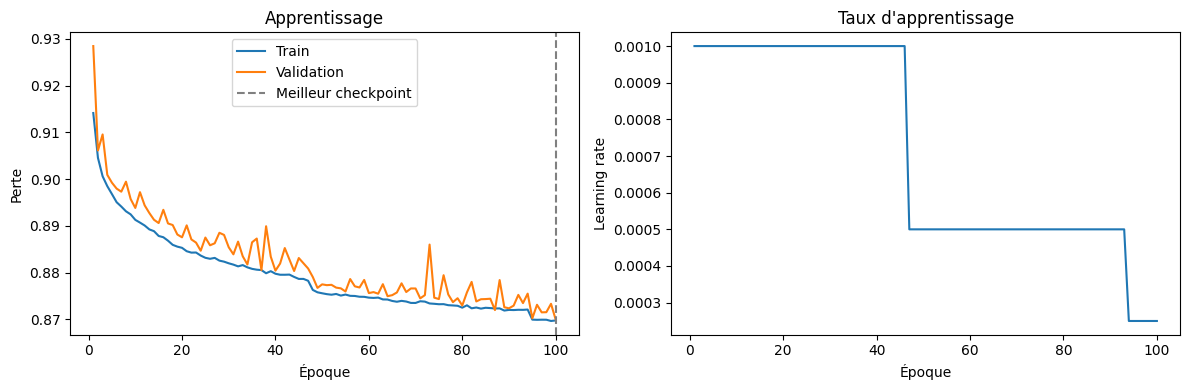

In [12]:
best_epoch = experiment.load_best()

print("Meilleure époque :", best_epoch)

plot_training(
    experiment.history_path,
    output_directory / "figures",
    best_epoch,
)


## 9. Évaluation des performances

Le modèle retenu est évalué sur la validation, le **test principal** et la **réserve U**. Pour chacun des six paramètres thermiques, les métriques calculées sont notamment :

- **MAE** : erreur absolue moyenne, exprimée dans l'unité du paramètre ;
- **RMSE** : racine de l'erreur quadratique moyenne, plus sensible aux erreurs importantes ;
- **$R^2$** : part de la variation des valeurs réelles expliquée par les prédictions, relativement à une référence constante.

Le modèle est également comparé à une référence prédisant les **moyennes du train**. Les résultats des tests servent à l'évaluation finale, et non à l'ajustement des hyperparamètres.

,partition,target,unit,MAE,RMSE,R2,bias
12,test,HLC,W/K,20.4148,25.6278,0.3321,0.3752
13,test,HLCext,W/K,12.7125,15.8065,0.1442,0.2205
14,test,HLCmit,W/K,18.4296,22.8777,0.2420,0.1547
15,test,tau_b,h,7.7925,9.9033,0.0343,-0.0679
16,test,tau_n,h,1.4384,1.8314,0.1693,0.0027
17,test,tau_inf,h,5.7735,7.3811,0.0341,-0.0328
24,reserve_u,HLC,W/K,20.2283,25.3601,0.3460,0.4884
25,reserve_u,HLCext,W/K,12.8019,15.8874,0.1350,0.4938
26,reserve_u,HLCmit,W/K,18.3115,22.7344,0.2517,-0.0054
27,reserve_u,tau_b,h,7.8152,9.9676,0.0313,-0.1522


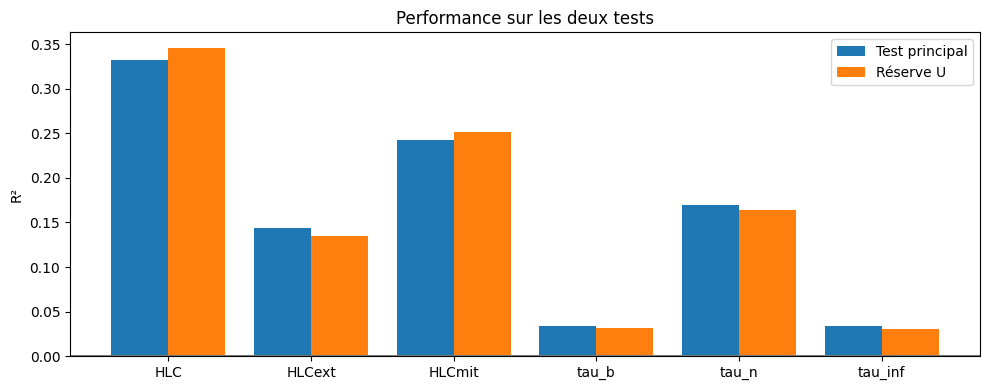

In [13]:
metrics = evaluate_all(experiment)

selected_metrics = metrics[
    (metrics["model"] == MODEL_KIND)
    & (metrics["partition"].isin(["test", "reserve_u"]))
]

display(
    selected_metrics[
        ["partition", "target", "unit", "MAE", "RMSE", "R2", "bias"]
    ].round(4)
)

plot_scores(metrics, MODEL_KIND, output_directory / "figures")


## 10. Analyse des prédictions et des valeurs extrêmes

Les diagrammes de dispersion comparent les prédictions aux valeurs réelles sur le test principal. La diagonale représente une prédiction parfaite ; les écarts à cette ligne illustrent les erreurs du modèle.

Une analyse complémentaire porte sur $\tau_b$ et $\tau_\infty$, dont l'estimation peut être plus difficile aux extrémités de leur distribution. Les régions étudiées sont définies par les **5e et 95e percentiles du train**. Les erreurs correspondantes sont ensuite calculées séparément sur le test principal et la réserve U.

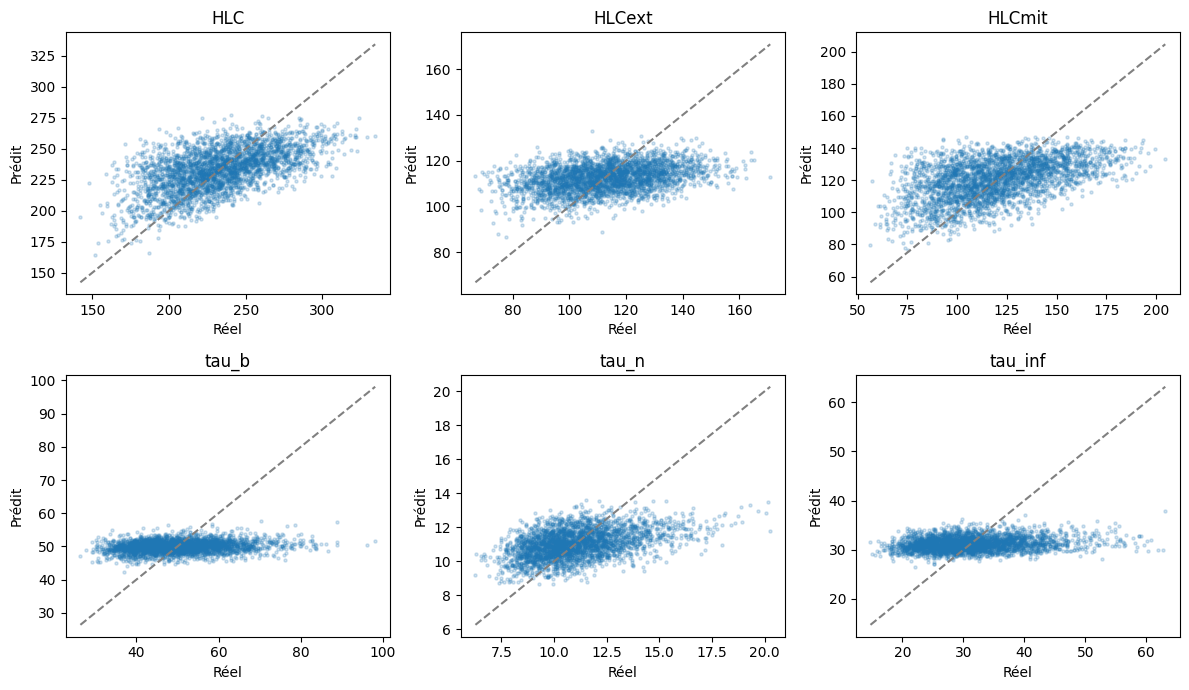

,partition,target,region,n,RMSE,bias
0,test,tau_b,5 % faibles,4447,16.209499,16.008499
1,test,tau_b,5 % élevés,4446,24.978001,-24.193600
2,test,tau_inf,5 % faibles,4475,11.582600,11.450800
3,test,tau_inf,5 % élevés,4399,19.170401,-18.504900
4,reserve_u,tau_b,5 % faibles,5055,16.200701,16.002800
5,reserve_u,tau_b,5 % élevés,5095,25.177900,-24.385099
6,reserve_u,tau_inf,5 % faibles,4987,11.590800,11.459600
7,reserve_u,tau_inf,5 % élevés,5094,19.249399,-18.578600


In [14]:
plot_scatter(
    output_directory / "predictions" / "test.npz",
    output_directory / "figures",
    seed=config.seed,
)

extreme_metrics = extreme_diagnostics(experiment)
display(extreme_metrics.round(4))


## 11. Sauvegarde des résultats

Les modèles entraînés, les configurations, les historiques d'entraînement, les métriques d'évaluation, les prédictions et les figures sont enregistrés afin d'assurer la traçabilité et la reproductibilité des expériences.

L'ensemble des résultats est également regroupé dans une archive ZIP.

In [ ]:
results_dir = Path("/kaggle/working/results/mlp/run_001")

if not (results_dir / "metrics.csv").exists():
    raise FileNotFoundError("Évaluation non terminée : metrics.csv absent.")

archive = shutil.make_archive(
    "/kaggle/working/mlp",
    "zip",
    root_dir=results_dir
)

file = Path(archive)

print("Fichier prêt :", file.exists())
print("Taille :", round(file.stat().st_size / 1024**2, 2), "Mo")
print("Nom :", file.name)


Fichier prêt : True
Taille : 11.23 Mo



## 12. Analyse et interprétation des résultats

Le perceptron multicouche (MLP) constitue notre modèle de référence. Il estime les paramètres thermiques à partir de 58 caractéristiques statistiques extraites des signaux de température et de sollicitation.

### Performances prédictives

| Paramètre | R² — Test | R² — Réserve U |
|---|---:|---:|
| HLC | 0.332 | 0.346 |
| HLCext | 0.144 | 0.135 |
| HLCmit | 0.242 | 0.252 |
| τb | 0.034 | 0.031 |
| τn | 0.169 | 0.164 |
| τ∞ | 0.034 | 0.031 |

Le modèle parvient à expliquer une partie de la variabilité des coefficients de déperdition thermique, notamment du HLC total. Les performances sont cependant limitées pour HLCext et particulièrement faibles pour les constantes de temps τb et τ∞.

Les graphiques de comparaison entre valeurs réelles et prédites mettent en évidence une concentration des prédictions autour des valeurs centrales. Cette sous-dispersion est particulièrement marquée pour τb et τ∞, dont les écarts-types prédits représentent respectivement environ 17 % et 18 % des écarts-types réels.

Les performances sur la réserve U restent proches de celles du test principal, sans dégradation majeure. Toutefois, cela ne garantit pas une généralisation à des bâtiments ou à des conditions physiques entièrement différents.

### Conclusion

Le MLP fournit une première référence expérimentale, mais les caractéristiques statistiques ne semblent pas restituer suffisamment toute l'information nécessaire à l'identification des paramètres thermiques. Cette observation motive l'étude de modèles exploitant directement les séries temporelles complètes.
